# 06 - Multiple Datasets & Bias Audit

This notebook answers two questions raised at our last presentation:

1. **Can the system work with more than one dataset?** Yes. We added the **South African Heart Disease (SAHeart)** dataset alongside the UCI Cleveland data, and rebuilt the pipeline in `src/` so a dataset is a plug-in rather than hard-coded.
2. **What is our bias?** We describe the bias built into each dataset, then measure it: how well the model works for different groups of patients (sex, age, family history), and whether a model trained on one population works on another.

### How the multi-dataset pipeline works

| Module | Role |
|---|---|
| `src/preprocessing.py` | One loader per raw file. Each returns the same target: `at_risk` (1 = coronary heart disease), whatever the file's own label encoding. |
| `src/feature_engineering.py` | Per-dataset engineered features using published clinical thresholds (AHA, NCEP, WHO). |
| `src/datasets.py` | **The registry.** One `DatasetSpec` per dataset: loader, features, bias-audit groups, and which features it shares with other datasets. |
| `src/train.py` | Trains the same 3 models (LR, RF, XGBoost) on any registered dataset and saves them to `models/<dataset>/`. |
| `src/evaluate.py` | Metrics, subgroup bias report with bootstrap confidence intervals, and the cross-dataset transfer test. |
| `src/bias_audit.py` | Runs everything and writes all tables to `reports/multi_dataset/`. |

**Adding a third dataset** means writing a loader, a feature function and one registry entry. Training and the bias audit then work on it unchanged.

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.datasets import DATASETS
from src.bias_audit import run_all
from src.evaluate import out_of_fold_probabilities

out = run_all(save=True)
results = out['results']
pd.set_option('display.precision', 3)

## 1. The two datasets

The two datasets measure **different things**. UCI has hospital test results (stress-test ECG, angiography vessel count, chest-pain type). SAHeart has **community risk-factor measurements** (tobacco, LDL cholesterol, BMI, alcohol, family history, Type-A behaviour). Only age and systolic blood pressure are measured the same way in both. That is why we train **one model per dataset** rather than pooling the rows: pooling would leave most columns empty for half the patients.

In [2]:
rows = []
for key, spec in DATASETS.items():
    p = out['profiles'][key]
    rows.append({'dataset': spec.title, 'source': spec.source, 'population': spec.population,
                 'rows': p['rows'], 'features': p['features'], 'CHD prevalence': p['prevalence'],
                 'age range': p['age_range']})
pd.DataFrame(rows).set_index('dataset')

,source,population,rows,features,CHD prevalence,age range
dataset,,,,,,
UCI Cleveland Heart Disease,"Cleveland Clinic Foundation (1988), via UCI / ...",303 US hospital patients referred for angiogra...,303,15,0.455,29-77
South African Heart Disease,"Coronary Risk-Factor Study, Western Cape (Rous...",462 men from a high-risk rural region of the W...,462,13,0.346,15-64


In [3]:
for key, res in results.items():
    print(f"{DATASETS[key].title}: {list(res.X.columns)}\n")

UCI Cleveland Heart Disease: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'hr_reserve', 'bp_risk_flag']

South African Heart Disease: ['sbp', 'tobacco', 'ldl', 'adiposity', 'famhist', 'typea', 'obesity', 'alcohol', 'age', 'bp_risk_flag', 'smoker', 'ldl_high', 'obese']



## 2. Model comparison on each dataset

The same three models run under the same 5-fold stratified cross-validation on each dataset. Class weighting is on because SAHeart is only 35% positive. The best model is picked by CV **ROC-AUC**, which is threshold-independent; recall alone can be gamed by a model that flags everyone.

In [4]:
for key, res in results.items():
    print(f"=== {DATASETS[key].title}  (best: {res.best_model}) ===")
    display(pd.concat({'5-fold CV': res.cv, 'held-out test': res.test.drop(columns='n')}, axis=1).round(3))

=== UCI Cleveland Heart Disease  (best: random_forest) ===


5-fold CV                                 held-out test  \
                     accuracy precision recall     f1 roc_auc      accuracy   
model                                                                         
logistic_regression     0.818     0.820  0.782  0.793   0.895         0.836   
random_forest           0.839     0.827  0.827  0.823   0.914         0.836   
xgboost                 0.818     0.808  0.800  0.799   0.904         0.820   

                                                     
                    precision recall     f1 roc_auc  
model                                                
logistic_regression     0.821  0.821  0.821   0.922  
random_forest           0.846  0.786  0.815   0.920  
xgboost                 0.840  0.750  0.792   0.923

=== South African Heart Disease  (best: logistic_regression) ===


5-fold CV                                 held-out test  \
                     accuracy precision recall     f1 roc_auc      accuracy   
model                                                                         
logistic_regression     0.683     0.532  0.672  0.590   0.743         0.667   
random_forest           0.675     0.524  0.625  0.569   0.732         0.656   
xgboost                 0.658     0.506  0.570  0.533   0.708         0.645   

                                                     
                    precision recall     f1 roc_auc  
model                                                
logistic_regression     0.509  0.875  0.644   0.819  
random_forest           0.500  0.750  0.600   0.757  
xgboost                 0.489  0.719  0.582   0.748

**Reading the results**

- **UCI: Random Forest wins** (CV ROC-AUC 0.914, test 0.920), the same choice as notebook 03.
- **SAHeart: Logistic Regression wins** (CV ROC-AUC 0.743, test 0.819). Tree models don't help here. SAHeart's risk factors relate to CHD in a smooth, mostly linear way, and with ~370 training rows the simpler model generalises better.
- **SAHeart is harder** (≈0.74 vs ≈0.91 CV AUC). That is expected, not a failure. UCI's strongest predictors (`ca`, `cp`, `exang`) are *test results from patients already in hospital with symptoms*. SAHeart only has risk factors you could collect at a community clinic, *before* symptoms appear. That is closer to our "silent killer" use case, and also harder.

> **Label direction:** the raw `heart.csv` encodes heart disease as `target=0`, while scikit-learn's recall scores class 1 by default. Notebook 01 and every `src/` loader flip the label to `at_risk = 1`, so all recall figures here (and in notebooks 03/04) are the share of **sick** patients caught. The small differences from notebook 03's numbers come from class weighting and slightly different hyperparameters.

## 3. Bias audit: does the model work equally well for everyone?

For every patient we take an **out-of-fold** prediction (from a model that never saw that patient), then compare groups on:

- **Recall**: of the patients who *have* heart disease, what share did we catch? A gap here means one group's disease is missed more often. This is the most serious kind of bias for a screening tool.
- **False positive rate (FPR)**: of the healthy patients, what share did we wrongly flag?
- **Flagged rate**: how often the model raises an alarm for the group at all.

Brackets are 95% bootstrap confidence intervals. With groups this small, overlapping intervals mean we can't be sure the gap is real.

In [5]:
for (key, col), table in out['subgroups'].items():
    print(f"=== {DATASETS[key].title} - by {col} ===")
    display(table[['n', 'n_at_risk', 'prevalence', 'flagged_rate', 'recall', 'recall_95ci', 'fpr', 'fpr_95ci', 'roc_auc']].round(3))

=== UCI Cleveland Heart Disease - by sex ===


,n,n_at_risk,prevalence,flagged_rate,recall,recall_95ci,fpr,fpr_95ci,roc_auc
group,,,,,,,,,
Female,96,24,0.250,0.240,0.792,0.59-0.94,0.056,0.01-0.12,0.916
Male,207,114,0.551,0.493,0.754,0.68-0.83,0.172,0.10-0.25,0.886


=== UCI Cleveland Heart Disease - by age_band ===


,n,n_at_risk,prevalence,flagged_rate,recall,recall_95ci,fpr,fpr_95ci,roc_auc
group,,,,,,,,,
<45,56,14,0.250,0.161,0.643,0.36-0.90,0.000,0.00-0.00,0.981
45-59,157,72,0.459,0.395,0.722,0.62-0.82,0.118,0.05-0.19,0.894
60+,90,52,0.578,0.600,0.846,0.74-0.94,0.263,0.13-0.41,0.868


=== South African Heart Disease - by age_band ===


,n,n_at_risk,prevalence,flagged_rate,recall,recall_95ci,fpr,fpr_95ci,roc_auc
group,,,,,,,,,
<45,227,44,0.194,0.172,0.409,0.26-0.55,0.115,0.07-0.16,0.736
45-59,171,84,0.491,0.713,0.833,0.75-0.91,0.598,0.49-0.70,0.699
60+,64,32,0.500,0.906,1.000,1.00-1.00,0.812,0.68-0.94,0.689


=== South African Heart Disease - by family_history ===


,n,n_at_risk,prevalence,flagged_rate,recall,recall_95ci,fpr,fpr_95ci,roc_auc
group,,,,,,,,,
Absent,270,64,0.237,0.296,0.531,0.41-0.66,0.223,0.17-0.28,0.721
Present,192,96,0.500,0.724,0.896,0.83-0.96,0.552,0.45-0.66,0.742


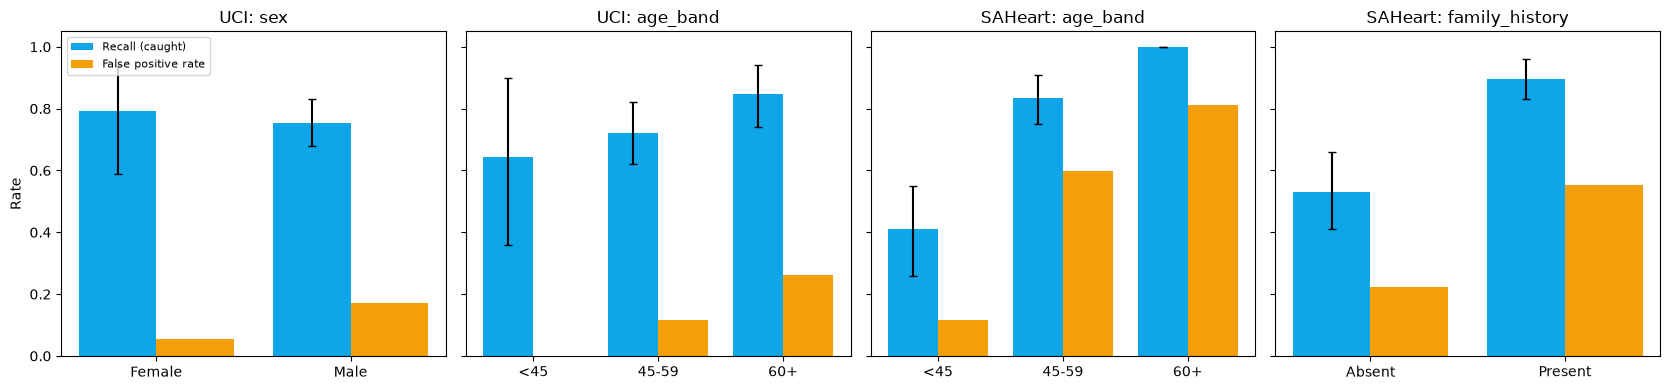

In [6]:
tables = list(out['subgroups'].items())
fig, axes = plt.subplots(1, len(tables), figsize=(4.2 * len(tables), 4), sharey=True)
for ax, ((key, col), t) in zip(axes, tables):
    x = np.arange(len(t))
    lo = [float(s.split('-')[0]) for s in t['recall_95ci']]
    hi = [float(s.split('-')[1]) for s in t['recall_95ci']]
    ax.bar(x - 0.2, t['recall'], 0.4, label='Recall (caught)', color='#0ea5e9',
           yerr=[t['recall'] - lo, np.array(hi) - t['recall']], capsize=3)
    ax.bar(x + 0.2, t['fpr'], 0.4, label='False positive rate', color='#f59e0b')
    ax.set_xticks(x, t.index)
    ax.set_title(f"{'UCI' if key == 'uci_heart' else 'SAHeart'}: {col}")
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel('Rate')
axes[0].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('../reports/multi_dataset/subgroup_recall_fpr.png', dpi=150)
plt.show()

In [7]:
out['gaps'].round(3)

,dataset,attribute,recall_gap,worst_recall_group,fpr_gap,highest_fpr_group,flag_ratio
0,uci_heart,sex,0.037,Male,0.116,Male,0.486
1,uci_heart,age_band,0.203,<45,0.263,60+,0.268
2,sa_heart,age_band,0.591,<45,0.698,60+,0.190
3,sa_heart,family_history,0.365,Absent,0.329,Present,0.409


### What the audit shows

**Sex (UCI only; SAHeart has no women).** Recall is about the same: 0.79 for women and 0.75 for men. So on this evidence the model does *not* miss women's disease more often. Two caveats:
- Only **24 women in the whole dataset have heart disease**, so the women's recall interval is very wide (0.59-0.94). We can't rule out a real gap.
- The model flags men about twice as often (49% vs 24%). That mostly follows the data: 55% of men vs 25% of women are positive. Women's heart disease often presents with atypical symptoms, and a sample this skewed may not have captured that.

**Age is our clearest bias.**
- **UCI:** under-45s have the lowest recall (0.64, only 14 positive cases), while 60+ get the most false alarms (FPR 0.26).
- **SAHeart:** the effect is severe. Under-45s with CHD are caught only **41%** of the time, while men aged 60+ are flagged almost automatically (recall 1.00 but **FPR 0.81**).

The model has learned *"older = sick"* as a shortcut. Age is a genuine risk factor, but over-relying on it means **young patients with heart disease are the ones most likely to be missed**. Those are exactly the "silent killer" cases this project is meant to find.

**Family history (SAHeart).** Men *without* a family history of heart disease have recall 0.53 vs 0.90 for those with one. Family history is a real risk factor, but the model leans on it so much that people with no known family history (including those who simply don't know their family's history) are under-detected.

### Mitigation: a lower decision threshold

Because missing a sick patient costs more than a false alarm, a lower threshold is a legitimate fix. Here is what it does for under-45s:

In [8]:
rows = []
for key, res in results.items():
    p = out_of_fold_probabilities(res.models[res.best_model], res.X, res.y)
    y = res.y.values
    young = (res.groups['age_band'] == '<45').values
    everyone = np.ones_like(y, dtype=bool)
    for t in [0.5, 0.4, 0.3]:
        pred = p >= t
        rows.append({'dataset': key, 'threshold': t,
                     'recall (all)': pred[everyone & (y == 1)].mean(), 'FPR (all)': pred[everyone & (y == 0)].mean(),
                     'recall (<45)': pred[young & (y == 1)].mean(), 'FPR (<45)': pred[young & (y == 0)].mean()})
pd.DataFrame(rows).set_index(['dataset', 'threshold']).round(2)

recall (all)  FPR (all)  recall (<45)  FPR (<45)
dataset   threshold                                                  
uci_heart 0.5                0.76       0.12          0.64       0.00
          0.4                0.86       0.23          0.86       0.05
          0.3                0.93       0.41          1.00       0.24
sa_heart  0.5                0.75       0.33          0.41       0.11
          0.4                0.82       0.42          0.55       0.18
          0.3                0.88       0.53          0.61       0.31

- **UCI:** dropping the threshold to **0.4** raises under-45 recall from 0.64 to **0.86**, with only 5% of healthy under-45s falsely flagged. Overall recall goes from 0.76 to 0.86. This is a cheap, defensible fix.
- **SAHeart:** a lower threshold helps young men only a little (0.41 to 0.61 at 0.3), and false alarms jump to 53% overall. The problem is the **data, not the threshold**: there are only 44 young CHD cases, and their risk-factor profiles look like those of healthy young men. Fixing this needs more data on young patients, not a different setting.

## 4. Does a model trained on one population work on another?

This test uses only the two features both datasets measure the same way (**age, systolic BP**). SAHeart is all male, so UCI is restricted to men for a like-for-like comparison. We compare:
- **in-domain**: the model cross-validated on the target dataset itself (best case)
- **transfer**: trained on the *other* dataset, tested on this one

In [9]:
out['transfer'].round(3)

,train_on,test_on,in_domain_auc,transfer_auc,transfer_flagged_rate,target_prevalence
0,uci_heart (men),sa_heart,0.719,0.722,0.297,0.346
1,sa_heart,uci_heart (men),0.661,0.672,0.758,0.551


**Result:** the *ranking* transfers. Transfer ROC-AUC (0.72 and 0.67) is about the same as in-domain (0.72 and 0.66). So the basic relationship (older + higher blood pressure = higher risk) holds in both a 1980s US hospital population and a 1980s rural South African community.

What does **not** transfer is the **calibration** (the probability scale). The model trained on SAHeart flags **76%** of UCI men when only 55% are positive. The UCI-trained model flags 30% of SAHeart men vs 35% positive. Each dataset has a different base rate (sampling design, hospital vs community), so **a model must be re-calibrated, with its threshold re-set, before it is used on a new population.** In the multi-dataset system, this is the reason each dataset gets its own model and threshold rather than one model for everyone.

## 5. Our bias statement

**Bias in the data (before any modelling)**

| Type | UCI Cleveland | SAHeart |
|---|---|---|
| **Selection / referral bias** | Patients already *referred to hospital for angiography*. 46% have disease, far above the general population. | **Case-control design**: about 2 healthy men were sampled per CHD case, so 35% prevalence is set by the study design, not by real-world rates. |
| **Sex** | 68% male; only 24 women with disease. | **100% male.** Says nothing about women. |
| **Geography & ethnicity** | One US clinic (Cleveland, Ohio). | One high-risk rural region of the Western Cape. Not representative of all South Africans. |
| **Era** | Collected in the 1980s. | Collected in the early 1980s. Treatment, diet and diagnostic standards have changed since. |
| **Measurement / timing** | Strongest predictors (`ca`, `cp`, `exang`) are tests done *after* symptoms appear. | Some CHD-positive men had **already started treatment** (e.g. BP medication) before measurement, which can make their risk factors look *lower* than they were. |
| **Size** | 303 rows | 462 rows |

**Bias in the model (measured above)**
1. **Age:** younger patients with heart disease are under-detected (UCI recall 0.64 for <45; SAHeart 0.41), while older patients get many false alarms.
2. **Family history:** men without a known family history are under-detected (SAHeart recall 0.53 vs 0.90).
3. **Sex:** no measurable recall gap on UCI, but the evidence for women is thin (24 positive cases) and SAHeart excludes women entirely.
4. **Population shift:** risk *ranking* transfers between populations, but probabilities need re-calibrating per population.

**What we did about it**
- Report recall and false-positive rates **per subgroup, with confidence intervals**, not just one overall score.
- Class weighting, so the minority (at-risk) class isn't ignored.
- Showed that a **0.4 threshold** largely closes the age gap on UCI at low cost.
- One model + threshold per dataset/population instead of assuming one model fits everyone.
- Fixed the label direction (`at_risk = 1`) so recall measures what we intend it to.

**What we would do next**
- Get data that includes **women, younger adults and current South African populations** (e.g. SANHANES / SADHS health survey data), then re-run this same audit on it via the registry.
- Re-calibrate probabilities (e.g. Platt scaling) on local data before any deployment.
- Monitor subgroup recall after deployment, not just overall accuracy.
- Treat this as a **screening aid that prompts a clinician**, never a diagnosis.